# Tutorial 6 — More models, more data, more control

The last tutorial collects everything that did not fit into the main line:

1. **committees** of models and their uncertainty (the basis of active learning);
2. the **autoencoder** model, `AutoencoderExcitedMACE`;
3. **missing labels** and per-frame **weights**;
4. **large data sets** with HDF5 preprocessing;
5. **free SOCs** and data from the original X-MACE;
6. **other multiplicities**: doublets and quartets;
7. **transfer learning** from ground-state foundation models, Stage Two, restarts;
8. the **Python API** for custom training loops.

**Requirements:** the SO2 data (Tutorial 2) and model (Tutorial 3); SHARC for the
reference curve in section 1. Runtime: about 15 minutes.

In [1]:
import json
import re
import shutil
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase
import ase.io
import matplotlib.pyplot as plt
import numpy as np
import torch

import mace  # noqa: F401

TUTORIAL = Path.cwd()
sys.path.insert(0, str(TUTORIAL / "tools"))
import so2_lvc as lvc

WORK = TUTORIAL / "work"
plt.rcParams.update({"figure.dpi": 100})
np.set_printoptions(precision=4, suppress=True, linewidth=120)
torch.set_default_dtype(torch.float64)  # the trained models are in float64


def strip(line):
    return re.sub(r"^\d{4}-\d\d-\d\d [\d:.]+ [A-Z]+: ", "", line)


def train(name, extra, directory, epochs=10, train_file="../so2_train.xyz"):
    """A short training run in work/<directory> (same settings as Tutorial 3)."""
    run = WORK / directory
    if run.exists():
        shutil.rmtree(run)  # MACE appends to existing log files
    run.mkdir(parents=True)
    command = [
        "mace_run_train", f"--name={name}", f"--train_file={train_file}", "--valid_fraction=0.1",
        "--model=ExcitedMACE", "--states=4 0 3", "--compute_nacs", "--compute_socs", "--compute_dipoles",
        "--E0s=average", "--r_max=5.0", "--hidden_irreps=32x0e + 32x1o", "--MLP_irreps=16x0e",
        "--num_interactions=2", "--correlation=2", "--batch_size=10", f"--max_num_epochs={epochs}",
        "--lr=0.01", "--ema", "--ema_decay=0.99", "--energy_weight=10", "--forces_weight=100",
        "--nacs_weight=10", "--socs_weight=1", "--dipoles_weight=1", "--default_dtype=float64",
        "--device=cpu",
    ] + extra
    result = subprocess.run(command, cwd=run, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError(f"training {name} failed")
    return (run / "logs" / f"{name}_run-{_seed(extra)}.log").read_text()


def _seed(extra):
    for item in extra:
        if item.startswith("--seed="):
            return item.split("=")[1]
    return "123"

## 1. Committees and uncertainty

A single model gives no idea of how much to trust a prediction. Training several
models that differ only in their random initialisation (`--seed`) gives a
**committee**: where the training data covers the geometry, the members agree;
where they extrapolate, they disagree. The spread is a cheap uncertainty estimate.

This is the core of **active learning**: run dynamics with the committee, collect
geometries where the spread is large, compute reference data there, retrain, repeat.

We train a second, quick model (20 epochs, seed 2) and combine it with the model of
Tutorial 3. A real committee would use 3–5 fully trained members.

In [2]:
log = train("so2_seed2", ["--seed=2"], "committee", epochs=20)
table = log[log.index("Error-table on TRAIN"):].splitlines()[:7]
print("\n".join(strip(line) for line in table))

Error-table on TRAIN and VALID:
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
|  config_type  | MAE E / meV | MAE E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles (x1e-3) |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
| train_Default |       15.7  |           5.2      |         92.3    |       3.73  |       230.85     |      3524.31     |          11.18      |
| valid_Default |       19.0  |           6.3      |        128.5    |       5.59  |       266.97     |      4020.22     |          12.33      |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+


committee of 2 models


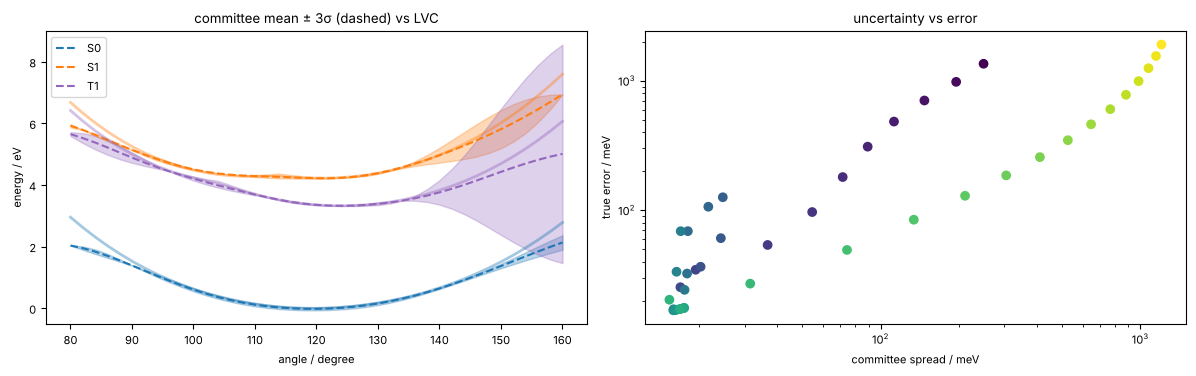

In [3]:
from mace.calculators import ExcitedMACECalculator

committee = ExcitedMACECalculator([str(WORK / "so2.model"), str(WORK / "committee" / "so2_seed2.model")], device="cpu")
print("committee of", committee.num_models, "models")

v0 = lvc.read_v0(WORK / "lvc_model" / "V0.txt")
r0 = np.linalg.norm(v0["coords"][1] - v0["coords"][0]) * lvc.BOHR_TO_ANGSTROM


def bend(angle_deg, r=r0):
    half = np.radians(angle_deg) / 2
    return np.array([[0, 0, 0], [0, -r * np.sin(half), r * np.cos(half)], [0, r * np.sin(half), r * np.cos(half)]])


angles = np.linspace(80, 160, 41)  # beyond the sampled range on both ends
positions = np.array([bend(a) for a in angles])
reference = lvc.lvc_reference(WORK / "lvc_model", positions / lvc.BOHR_TO_ANGSTROM)
ref_energies = np.array([np.diag(h).real[:7] for h in reference["h"]]) * 27.211386
predictions = [committee.predict(ase.Atoms(v0["symbols"], positions=p)) for p in positions]
mean = np.array([p["energies"] for p in predictions])
spread = np.sqrt(np.array([p["energies_var"] for p in predictions]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s in (0, 1, 4):
    axes[0].plot(angles, ref_energies[:, s], lw=2, alpha=0.4, color=f"C{s}")
    axes[0].fill_between(angles, mean[:, s] - 3 * spread[:, s], mean[:, s] + 3 * spread[:, s], color=f"C{s}", alpha=0.3)
    axes[0].plot(angles, mean[:, s], ls="--", color=f"C{s}", label=["S0", "S1", "", "", "T1"][s])
axes[0].set(xlabel="angle / degree", ylabel="energy / eV", title="committee mean ± 3σ (dashed) vs LVC")
axes[0].legend()
error = np.abs(mean - ref_energies).max(axis=1)
axes[1].scatter(spread.max(axis=1) * 1000, error * 1000, c=angles, cmap="viridis")
axes[1].set(xlabel="committee spread / meV", ylabel="true error / meV", title="uncertainty vs error", xscale="log", yscale="log")
plt.tight_layout()

The spread grows towards the ends of the scan, outside the training data, together
with the true error (right: one point per geometry, coloured by the bend angle). In SHARC, give a glob pattern as `model_file`
(`so2*.model`) and the committee mean drives the dynamics.

## 2. `AutoencoderExcitedMACE`

`ExcitedMACE` predicts each state's energy with its own readout. Nothing forces
state *i* to stay below state *i+1*, and near a conical intersection the two
readouts must produce the cusp of the adiabatic surfaces.

`AutoencoderExcitedMACE` predicts instead a permutation-invariant latent vector,
from which a decoder builds a symmetric tridiagonal matrix; **the energies are its
eigenvalues**. They are ordered by construction, and crossings come out of the
eigenvalue problem naturally. With several multiplicities the matrix has one block
per multiplicity, so the states are ordered **within each multiplicity**, like
SHARC's MCH states (a triplet may lie below a singlet). During training an encoder
maps the reference energies into the same latent space; the loss asks the decoder to
reconstruct them and the network to reproduce the encoded vector. Use it when states
cross often; the options are the same plus `--num_permutational_invariant` (latent
size).

In [4]:
log = train("so2_ae", ["--model=AutoencoderExcitedMACE", "--num_permutational_invariant=16", "--seed=3"], "autoencoder", epochs=10)
for line in log.splitlines():
    if "AutoencoderExcitedMACE:" in line or "Epoch 9:" in line:
        print(strip(line)[:240])
ae = ExcitedMACECalculator(str(WORK / "autoencoder" / "so2_ae.model"), device="cpu")
energies = np.array([ae.predict(ase.Atoms(v0["symbols"], positions=p))["energies"] for p in positions[:, :, :]])
# 10 epochs are far too few for a good model; this only shows how to train one
singlets_ordered = np.all(np.diff(energies[:, :4], axis=1) >= 0)
triplets_ordered = np.all(np.diff(energies[:, 4:], axis=1) >= 0)
print("singlets ordered along the scan:", bool(singlets_ordered), "| triplets ordered:", bool(triplets_ordered))

AutoencoderExcitedMACE: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit), dipoles=16, coupling parity=both, pair repulsion=off
Epoch 9: head: Default, loss=8.48981035, MAE_E=  274.17 meV, MAE_E_per_atom=   91.39 meV, MAE_F=  220.28 meV / A, MAE_NACs=  336.96 (x1e-3), MAE_SOCs= 5366.57 (x1e-3), MAE_dipoles=   14.99 (x1e-3)


singlets ordered along the scan: True | triplets ordered: True


## 3. Missing labels and weights

Real data sets are rarely complete: some calculations have no NACs (they are
expensive), SOCs were computed only for some geometries, a few points failed. X-MACE
handles this per label: a missing label is filled with zeros and gets weight 0, so
that frame is skipped **for that loss term only**. Per-frame weights work as in
MACE: `config_weight` (all terms) and `config_<property>_weight` in `atoms.info`.

In [5]:
frames = ase.io.read(WORK / "so2_train.xyz", ":")
rng = np.random.default_rng(0)
for atoms in frames:
    if rng.random() < 0.5:
        del atoms.info["REF_socs"]  # no SOCs for half of the frames
    if rng.random() < 0.3:
        del atoms.info["REF_nacs"]  # no NACs for 30 %
    if rng.random() < 0.1:
        atoms.info["config_weight"] = 0.5  # trust these frames less
ase.io.write(WORK / "so2_partial.xyz", frames)
log = train("partial", ["--seed=4"], "partial", epochs=1, train_file="../so2_partial.xyz")
print("\n".join(strip(l) for l in log.splitlines() if "Excited-state labels" in l))

Excited-state labels in train set of head 'Default' (593 configurations): energy=593, forces=593, nacs=421, socs=300, dipoles=593
Excited-state labels in valid set of head 'Default' (65 configurations): energy=65, forces=65, nacs=44, socs=28, dipoles=65


## 4. Large data sets: HDF5

For tens of thousands of frames, reading XYZ files and building graphs at every
start becomes slow. `mace_prepare_data` (the script `mace/cli/preprocess_data.py`) converts the data (including all
excited-state labels) to HDF5 once, and computes the statistics (E0s, scale, one
shift per state):

In [6]:
h5 = WORK / "h5"
subprocess.run(
    ["mace_prepare_data", f"--train_file={WORK / 'so2_train.xyz'}", "--valid_fraction=0.1",
     f"--h5_prefix={h5}/", "--r_max=5.0", "--E0s=average", "--compute_statistics",
     "--states=4 0 3", "--compute_nacs", "--compute_socs", "--compute_dipoles", "--num_process=1", "--seed=1"],
    check=True, capture_output=True,
)
print(json.loads((h5 / "statistics.json").read_text()))
print(sorted(p.relative_to(h5).as_posix() for p in h5.rglob("*.h5")))

{'atomic_energies': '{8: 1.7233899255717404, 16: 0.8616949627858713}', 'avg_num_neighbors': 2.0, 'mean': [-1.2002489566802979, -0.05021153762936592, 0.1691104769706726, 1.3389277458190918, -0.252568781375885, -0.06598671525716782, 0.06097735837101936], 'std': 3.748506546020508, 'atomic_numbers': '[8, 16]', 'r_max': 5.0}
['train/train_0.h5', 'val/val_0.h5']


Train from the HDF5 files with the same model options:

```bash
mace_run_train --model=ExcitedMACE --states="4 0 3" --compute_nacs --compute_socs \
  --compute_dipoles --train_file=h5/train/train_0.h5 --valid_file=h5/val/val_0.h5 \
  --statistics_file=h5/statistics.json ...
```

## 5. Free SOCs and data from the original X-MACE

`--soc_mode=free` learns the SOCs as `--soc_num` invariant numbers per frame, without
any assumption about their structure. Use it for SOC data that is not in SHARC's
convention and cannot be converted, or for X-MACE data sets. The original X-MACE
stored the upper triangle of the M_S-resolved SOC matrix as real numbers; with
`--soc_num` equal to its length, the SHARC interface still builds the full
Hermitian matrix. The price: no symmetry constraints (no selection rules, no
rotation covariance), so more data is needed.

X-MACE command lines keep working: `--n_energies=3 --compute_nacs --compute_socs
--soc_num=...` without `--states` trains states of one multiplicity with free SOCs.

In [7]:
from types import SimpleNamespace

from mace.data.excited import excited_spec_from_args

common = dict(model="ExcitedMACE", compute_nacs=True, compute_socs=True, compute_dipoles=True, nac_num=None,
              dipole_num=None, nacs_format="raw", nacs_key="REF_nacs")
for options in (
    dict(states="4 0 3", n_energies=None, soc_num=None, soc_mode="auto"),
    dict(states="4 0 3", n_energies=None, soc_num=78, soc_mode="free"),
    dict(states=None, n_energies=3, soc_num=3, soc_mode="auto"),
):
    spec = excited_spec_from_args(SimpleNamespace(**common, **options))
    print(f"{options} ->\n   {spec.describe()}")

{'states': '4 0 3', 'n_energies': None, 'soc_num': None, 'soc_mode': 'auto'} ->
   7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit), dipoles=16
{'states': '4 0 3', 'n_energies': None, 'soc_num': 78, 'soc_mode': 'free'} ->
   7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=78, dipoles=16
{'states': None, 'n_energies': 3, 'soc_num': 3, 'soc_mode': 'auto'} ->
   3 states, NACs=3 (raw), SOCs=3, dipoles=6


## 6. Doublets and quartets

Radicals have doublet and quartet states: `--states="0 3 0 2"` means 3 doublets and 2
quartets. Everything works as for singlets and triplets: each doublet has two M_S
components (±1/2), each quartet four; NACs couple D–D and Q–Q; SOC vectors couple
D–D, D–Q and Q–Q pairs. A quick look with an untrained model:

In [8]:
from e3nn import o3

from mace import modules, tools
from mace.calculators.sharc_calculator import SharcCalculator
from mace.modules.spin_states import describe_states, n_mstates, spin_orbit_pairs

radical_states = [0, 3, 0, 2]
z_table = tools.AtomicNumberTable([1, 6, 8])
torch.manual_seed(0)
radical = modules.ExcitedMACE(
    r_max=4.0, num_bessel=8, num_polynomial_cutoff=5, max_ell=2,
    interaction_cls=modules.interaction_classes["RealAgnosticResidualInteractionBlock"],
    interaction_cls_first=modules.interaction_classes["RealAgnosticInteractionBlock"],
    num_interactions=2, num_elements=3, hidden_irreps=o3.Irreps("16x0e + 16x1o"),
    MLP_irreps=o3.Irreps("16x0e"), atomic_energies=np.zeros(3), avg_num_neighbors=3.0,
    atomic_numbers=z_table.zs, correlation=2, gate=torch.nn.functional.silu,
    n_energies=sum(radical_states), states=radical_states,
    compute_nacs=True, compute_socs=True, soc_mode="spin_orbit",
)
torch.save(radical, WORK / "radical.model")
print(describe_states(radical_states), "|", n_mstates(radical_states), "M_S states |",
      radical.nac_num, "NACs |", radical.soc_vector_num, "SOC vectors:", spin_orbit_pairs(radical_states))

hco = ase.Atoms("HCO", positions=[[0.0, 1.08, -0.55], [0.0, 0.0, 0.0], [0.0, 0.1, 1.18]])  # formyl radical
sharc = SharcCalculator(hco.get_chemical_symbols(), str(WORK / "radical.model"), states=radical_states,
                        properties=["energy", "forces", "nacs", "socs"])
qm = sharc.calculate(hco.positions / lvc.BOHR_TO_ANGSTROM)
print("h:", qm["h"].shape, "| Hermitian:", np.allclose(qm["h"], qm["h"].conj().T))
print("doublet energies (Hartree), M_S = -1/2 then +1/2:", np.diag(qm["h"]).real[:6].round(4))

3 doublets, 2 quartets | 14 M_S states | 4 NACs | 10 SOC vectors: [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]


h: (14, 14) | Hermitian: True
doublet energies (Hartree), M_S = -1/2 then +1/2: [-0.0012 -0.0031 -0.0035 -0.0012 -0.0031 -0.0035]


In SHARC set `nstates 0 3 0 2` and one charge per multiplicity, e.g. `charge 0 0 0 0`.

## 7. Transfer learning, Stage Two and restarts

* **Foundation models.** `--foundation_model=medium_off` (or `small`, `medium`,
  `large`, `*_off`, or a path to any MACE model) copies the backbone of a
  ground-state MACE foundation model; with `--foundation_model_readout=True` every
  state starts from the foundation's energy readout. The model reproduces the
  foundation's ground-state surface for every state before training, which helps
  with small data sets. The architecture options (`--hidden_irreps`, `--r_max`, ...)
  then come from the foundation model.
* **Stage Two** (`--swa --start_swa=<epoch> --swa_energy_weight=... --swa_forces_weight=...`):
  for the last epochs, a lower learning rate and different loss weights, typically a
  higher energy weight.
* **Restarts:** `--restart_latest` continues from the last checkpoint in
  `checkpoints/`.
* **float32 and GPUs:** `--default_dtype=float32 --device=cuda` trains much faster;
  evaluate in float64 if you need very smooth surfaces.

## 8. The Python API

Everything the command line does is available from Python, for custom training
loops or new kinds of data. The pieces:

* `mace.data.excited.ExcitedStateSpec` — what the model predicts;
* `standardise_excited_configs` — converts labels to the model layout (smooth NACs,
  SOC vectors, missing labels → weight 0);
* `mace.modules.ExcitedMACE` / `AutoencoderExcitedMACE` — the models;
* `mace.modules.WeightedExcitedStatesLoss` — the phase-free loss;
* `mace.modules.spin_states` — state order, selection rules, SOC matrices.

In [9]:
from mace import data
from mace.data.excited import ExcitedStateSpec, standardise_excited_configs
from mace.modules.spin_states import same_multiplicity_pairs, soc_pair_weights
from mace.tools import torch_geometric

states = [4, 0, 3]
pairs = same_multiplicity_pairs(states)
spec = ExcitedStateSpec(n_states=7, n_nacs=len(pairs), n_dipoles=7 + len(pairs), states=states, soc_mode="spin_orbit")
keyspec = data.KeySpecification(
    info_keys={"energy": "REF_energy", "socs": "REF_socs", "dipoles": "REF_dipoles"},
    arrays_keys={"forces": "REF_forces", "nacs": "REF_nacs"},
)
configs = [data.config_from_atoms(a, key_specification=keyspec) for a in ase.io.read(WORK / "so2_train.xyz", ":40")]
standardise_excited_configs(configs, spec)
z_table = tools.AtomicNumberTable([8, 16])
graphs = [data.AtomicData.from_config(c, z_table=z_table, cutoff=5.0) for c in configs]
loader = torch_geometric.dataloader.DataLoader(graphs, batch_size=10, shuffle=True)

model = torch.load(WORK / "so2.model", weights_only=False)  # continue from the trained model
weights = soc_pair_weights(states)
loss_fn = modules.WeightedExcitedStatesLoss(
    energy_weight=10.0, forces_weight=100.0, nacs_weight=10.0, socs_weight=1.0, dipoles_weight=1.0,
    n_permanent_dipoles=spec.n_permanent_dipoles, soc_pair_weights=weights / weights.mean(), soc_states=states,
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
for step, batch in enumerate(loader):
    optimizer.zero_grad()
    output = model(batch.to_dict(), training=True, compute_force=True)
    loss = loss_fn(batch, output)
    loss.backward()
    optimizer.step()
    print(f"step {step}: loss {loss.item():.4f}, outputs: {sorted(k for k, v in output.items() if v is not None)[:6]} ...")

step 0: loss 39.6372, outputs: ['contributions', 'dipoles', 'displacement', 'energy', 'forces', 'nacs'] ...


step 1: loss 28.1727, outputs: ['contributions', 'dipoles', 'displacement', 'energy', 'forces', 'nacs'] ...


step 2: loss 58.5882, outputs: ['contributions', 'dipoles', 'displacement', 'energy', 'forces', 'nacs'] ...


step 3: loss 37.8824, outputs: ['contributions', 'dipoles', 'displacement', 'energy', 'forces', 'nacs'] ...


These are losses per batch. The validation loss in the training log is divided by
the batch size (a MACE convention), so it is about ten times smaller for
`--batch_size=10`.

## Where to go from here

* `XMACE.md` in the repository root describes every option and the data format.
* `tests/excited/` contains small, readable examples of every feature.
* For a new molecule: generate reference data with your quantum-chemistry method
  through SHARC (Tutorial 2), check the SOC residual, train (Tutorial 3), validate
  along scans and against a few reference trajectories (Tutorials 4–5), and improve
  the data where a committee disagrees.